# Lab 12 Walkthrough: Non-Linear Regression and Spatial Evaluation

You will predict the median house value of a California neighborhood with four models (a straight line, a decision tree, a random forest, gradient boosting) and then ask the question the lecture ended on: **does a good score on random held-out rows hold in a place the model has not seen?**

Every random choice uses a fixed `random_state`, so your numbers should match the ones printed here. Boxes marked **🔎 Try it yourself** are not graded. The graded tasks are in `lab12-tasks.ipynb`.

| Part | Topic |
|---|---|
| 0 | Versions, imports, helpers |
| 1 | The data |
| 2 | A line, learning as a loop, train/test split and scores |
| 3 | More bends, more risk: polynomials |
| 4 | A decision tree and its depth |
| 5 | A random forest |
| 6 | Gradient boosting and tuning with cross-validation |
| 7 | Add latitude and longitude, random versus spatial folds |
| 8 | Where the model fails: the residual map |
| 9 | What the forest uses: permutation importance |

## Part 0: Setup

The first cell prints the package versions. The packages are `scikit-learn` (models and scores), `geopandas` (to project coordinates to meters), `libpysal` and `esda` (Moran's I).

In [1]:
import sys, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from sklearn import cluster, ensemble, inspection, linear_model, metrics, model_selection, tree
from libpysal import weights
from esda import Moran

print("Python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__, "| geopandas", gpd.__version__,
      "| scikit-learn", sklearn.__version__, "| matplotlib", matplotlib.__version__)

Python 3.8.16 | numpy 1.24.3 | pandas 2.0.2 | geopandas 0.13.2 | scikit-learn 1.2.2 | matplotlib 3.7.1


In [2]:
PURPLE, MAGENTA, BLUE, GRAY = "#7C3AED", "#DB2777", "#2563EB", "#6B6478"
plt.rcParams.update({"font.size": 12, "axes.spines.top": False, "axes.spines.right": False})


def rmse(y_true, y_pred):
    """Root mean squared error (scikit-learn 1.2.2 has no root_mean_squared_error)."""
    return float(np.sqrt(metrics.mean_squared_error(y_true, y_pred)))


def scores(model, X_tr, y_tr, X_te, y_te):
    """Train R2, test R2, test MAE, test RMSE of a fitted model."""
    p = model.predict(X_te)
    return dict(train_r2=model.score(X_tr, y_tr), test_r2=model.score(X_te, y_te),
                mae=metrics.mean_absolute_error(y_te, p), rmse=rmse(y_te, p))


def blank(ax):
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(False)


def point_map(ax, x, y, values, cmap, vmin, vmax, title, label):
    """Scatter map of block groups (projected meters), no ticks, with a colorbar."""
    sc = ax.scatter(x, y, c=values, s=3, cmap=cmap, vmin=vmin, vmax=vmax, linewidths=0)
    ax.set_aspect("equal"); blank(ax); ax.set_title(title)
    cb = plt.colorbar(sc, ax=ax, shrink=0.7); cb.set_label(label)

## Part 1: The data

**California Housing** is built from the 1990 US Census (Pace and Barry, 1997; the copy distributed with `scikit-learn`). One row is one **block group**, a small census area of a few hundred to a few thousand people. There are 20,640 rows.

| Column | Meaning |
|---|---|
| `MedHouseVal` | Median house value, in units of 100,000 dollars. This is the **target**, the number we predict. It is capped at 5.00001 (992 block groups sit at the cap) |
| `MedInc` | Median household income, in units of 10,000 dollars |
| `HouseAge` | Median age of the houses, in years |
| `AveRooms`, `AveBedrms` | Average rooms and bedrooms per household |
| `Population` | People living in the block group |
| `AveOccup` | Average people per household |
| `Latitude`, `Longitude` | Block group center, in degrees |

We also project the coordinates to meters (`x`, `y`, EPSG:3310, California Albers), which is needed to measure distances and build neighbors.

In [3]:
df = pd.read_csv("data/california_housing.csv")
xy = gpd.GeoSeries(gpd.points_from_xy(df.Longitude, df.Latitude), crs=4326).to_crs(3310)   # California Albers, meters
df["x"], df["y"] = xy.x.values, xy.y.values
print(df.shape)
df.head()

(20640, 11)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal,x,y
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526,-195862.241798,-12855.761544
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585,-195036.152753,-15099.103049
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521,-196819.172199,-16169.133560
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413,-197697.664622,-16148.327582
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422,-197697.664622,-16148.327582


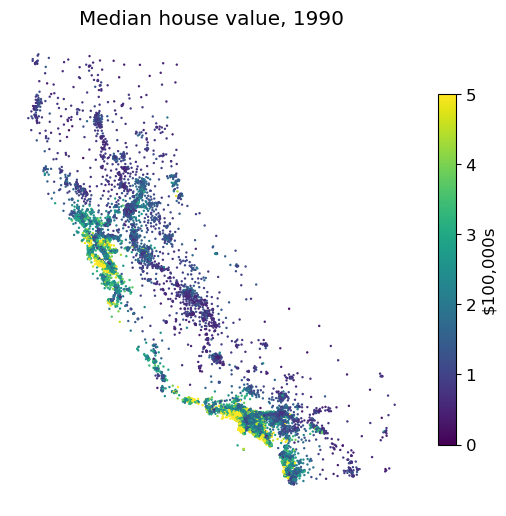

share at the cap: 0.048


In [4]:
fig, ax = plt.subplots(figsize=(6.5, 6.5))
point_map(ax, df.x, df.y, df.MedHouseVal, "viridis", 0, 5, "Median house value, 1990", "$100,000s")
plt.show()
print("share at the cap:", round((df.MedHouseVal >= 5).mean(), 3))

The coast is expensive and the interior is not, and the high values cluster around San Francisco and Los Angeles. A model that ignores location will miss this. Hold that thought for Part 7.

### 🔎 Try it yourself
Make the same map for `MedInc`. Does it look like the value map? Where does it differ?

## Part 2: A line, learning as a loop, and scoring

### Learning is a loop

The straight line $\hat{y} = b_0 + b_1 x$ has two knobs, the intercept $b_0$ and the slope $b_1$. "Learning" means a rule that turns the knobs to shrink the error. **Gradient descent** repeats three steps: predict, measure the error, nudge each knob a little in the direction that lowers the error. We do it by hand on a small sample of 30 block groups, with income as $x$. A **rate** controls the size of each nudge.

In [5]:
s = df.sample(30, random_state=0)
xs, ys = s.MedInc.values, s.MedHouseVal.values
b0, b1, rate = 0.0, 0.0, 0.005
for step in range(100):
    pred = b0 + b1 * xs                      # 1. predict
    err = pred - ys                          # 2. measure the error
    b0 -= rate * err.sum() * 2 / len(xs)     # 3. nudge each knob downhill on the squared error
    b1 -= rate * (err * xs).sum() * 2 / len(xs)
    if step in (0, 9, 99):
        print(f"step {step + 1:3d}: intercept {b0:.3f}, slope {b1:.3f}, mean squared error {np.mean(err ** 2):.3f}")
print("least squares answer:", np.polyfit(xs, ys, 1)[::-1].round(3))

step   1: intercept 0.021, slope 0.092, mean squared error 5.758
step  10: intercept 0.107, slope 0.450, mean squared error 0.791
step 100: intercept 0.159, slope 0.521, mean squared error 0.623
least squares answer: [0.399 0.466]


The error falls at every step. After 100 steps the knobs are still moving toward the least-squares answer printed last (a larger rate or more steps would get closer). A forest has millions of knobs and a different update rule, but the loop is the same: predict, measure, update.

### Train/test split

A model can be tuned until it fits the rows it saw. To find out how it does on new rows, we **hold out** a test set that the model never sees while fitting. `train_test_split` shuffles the rows and sets 20% aside; `random_state=0` makes the shuffle repeatable.

In [6]:
F6 = ["MedInc", "HouseAge", "AveRooms", "AveBedrms", "Population", "AveOccup"]
F8 = F6 + ["Latitude", "Longitude"]
y = df["MedHouseVal"]
X_train, X_test, y_train, y_test = model_selection.train_test_split(df[F6], y, test_size=0.2, random_state=0)
print(X_train.shape, X_test.shape)

(16512, 6) (4128, 6)


In [7]:
lr = linear_model.LinearRegression().fit(X_train, y_train)
sc = scores(lr, X_train, y_train, X_test, y_test)
print({k: round(v, 3) for k, v in sc.items()})

{'train_r2': 0.543, 'test_r2': 0.525, 'mae': 0.581, 'rmse': 0.787}


Three scores, all on the **test** rows:
- **$R^2$** is the share of the variation in value that the model explains (1 is perfect, 0 is no better than always predicting the mean).
- **MAE** (mean absolute error) is the typical miss, in the data's units: 0.58 means about 58,000 dollars.
- **RMSE** (root mean squared error) is also in the data's units but squares the misses first, so a few large misses count more.

The test $R^2$ is about the same as the train $R^2$: a line has too little freedom to memorize.

### 🔎 Try it yourself
Fit the line on `MedInc` alone. What is the test $R^2$ now? Which of the other five features adds the most?

## Part 3: More bends, more risk

Income is close to a straight line against value, so a bend will not show there. Latitude is different: value rises and falls as you move north. We draw 40 block groups, fit polynomials of degree 1, 6 and 15 (a degree-$d$ polynomial has $d + 1$ knobs), and score each on 40 *other* block groups from the same range of latitude. `np.polyfit` fits the polynomial.

In [8]:
rng = np.random.RandomState(1)
lat = df[["Latitude", "MedHouseVal"]]
pick = rng.choice(len(lat), 80, replace=False)
tr_s, te_s = lat.iloc[pick[:40]], lat.iloc[pick[40:]]
te_s = te_s[(te_s.Latitude >= tr_s.Latitude.min()) & (te_s.Latitude <= tr_s.Latitude.max())]   # stay inside the sampled range
mu, sd = tr_s.Latitude.mean(), tr_s.Latitude.std()                     # center and scale: high degrees are unstable otherwise
f = lambda v: (v - mu) / sd
for deg in (1, 6, 15):
    c = np.polyfit(f(tr_s.Latitude), tr_s.MedHouseVal, deg)
    e_tr = rmse(tr_s.MedHouseVal, np.polyval(c, f(tr_s.Latitude)))
    e_te = rmse(te_s.MedHouseVal, np.polyval(c, f(te_s.Latitude)))
    print(f"degree {deg:2d}: train RMSE {e_tr:5.2f}, test RMSE {e_te:6.2f}")

degree  1: train RMSE  1.05, test RMSE   1.08
degree  6: train RMSE  1.02, test RMSE   1.07
degree 15: train RMSE  0.78, test RMSE  50.67


The training error keeps falling as the degree rises. The test error does not: a degree-15 curve threads every training point and then swings wildly between and beyond them. This is **overfitting**: the model memorized noise. The degree is a **hyperparameter**, a setting we choose before fitting rather than one the loop learns.

### 🔎 Try it yourself
Change the seed in `RandomState(1)` and rerun. Is the ranking of the three degrees on the test rows stable?

## Part 4: A decision tree and its depth

A **decision tree** asks yes/no questions about the features ("is `MedInc` below 5.03?") and predicts the **average value of the training rows in the final group** (a leaf). At each question it picks the split that most reduces the squared error. `DecisionTreeRegressor` from `sklearn.tree` does this. The hyperparameter `max_depth` limits how many questions in a row are allowed.

In [9]:
rows = []
for depth in (1, 2, 3, 5, 8, 12, None):
    t = tree.DecisionTreeRegressor(max_depth=depth, random_state=0).fit(X_train, y_train)
    rows.append(dict(max_depth=str(depth), leaves=t.get_n_leaves(), train_r2=t.score(X_train, y_train), test_r2=t.score(X_test, y_test)))
pd.DataFrame(rows).round(3)

,max_depth,leaves,train_r2,test_r2
0,1,2,0.316,0.284
1,2,4,0.454,0.418
2,3,8,0.542,0.499
3,5,32,0.637,0.580
4,8,236,0.725,0.611
5,12,1887,0.859,0.484
6,None,15907,1.000,0.354


In [10]:
t3 = tree.DecisionTreeRegressor(max_depth=3, random_state=0).fit(X_train, y_train)
print(tree.export_text(t3, feature_names=F6))

|--- MedInc <= 5.03
|   |--- MedInc <= 3.07
|   |   |--- AveRooms <= 4.31
|   |   |   |--- value: [1.61]
|   |   |--- AveRooms >  4.31
|   |   |   |--- value: [1.16]
|   |--- MedInc >  3.07
|   |   |--- AveOccup <= 2.37
|   |   |   |--- value: [2.79]
|   |   |--- AveOccup >  2.37
|   |   |   |--- value: [1.88]
|--- MedInc >  5.03
|   |--- MedInc <= 6.82
|   |   |--- AveOccup <= 2.74
|   |   |   |--- value: [3.41]
|   |   |--- AveOccup >  2.74
|   |   |   |--- value: [2.57]
|   |--- MedInc >  6.82
|   |   |--- MedInc <= 7.82
|   |   |   |--- value: [3.71]
|   |   |--- MedInc >  7.82
|   |   |   |--- value: [4.60]



With no limit (`None`) the tree grows until every leaf holds one block group: the training $R^2$ is 1.000 and the test $R^2$ is *lower than a depth-3 tree*. Depth is the knob that trades fit against memorization.

Read the printed tree top to bottom: each `|---` line is a question, each `value` is the leaf's average.

### 🔎 Try it yourself
Add `min_samples_leaf=20` to the unlimited tree. A leaf must now hold at least 20 block groups. What happens to the train and test $R^2$?

## Part 5: A random forest

One tree memorizes, but different trees memorize different things. A **random forest** (`RandomForestRegressor` in `sklearn.ensemble`; Breiman, 2001) grows many trees, each on a **bootstrap** sample (rows drawn with replacement) and with a random subset of features at each split, and **averages** their predictions. The memorized noise differs between trees, so it tends to cancel in the average.

In [11]:
rf = ensemble.RandomForestRegressor(n_jobs=-1, random_state=0).fit(X_train, y_train)       # 100 trees by default
for name, m in [("line", lr), ("forest", rf)]:
    print(name, {k: round(v, 3) for k, v in scores(m, X_train, y_train, X_test, y_test).items()})
print("nodes in the forest:", sum(e.tree_.node_count for e in rf.estimators_))

line {'train_r2': 0.543, 'test_r2': 0.525, 'mae': 0.581, 'rmse': 0.787}
forest {'train_r2': 0.957, 'test_r2': 0.669, 'mae': 0.47, 'rmse': 0.657}
nodes in the forest: 2018316


The forest beats the line on the test rows. Its training $R^2$ is still much higher than its test $R^2$, so it still memorizes, but its test score is what counts.

### 🔎 Try it yourself
Fit forests with `n_estimators` of 1, 10 and 100. How does the test $R^2$ change? Does it stop improving?

## Part 6: Gradient boosting and tuning

A forest grows its trees independently. **Gradient boosting** (`GradientBoostingRegressor`; Friedman, 2001) grows them in sequence: start from the average, fit a small tree to the **leftover errors**, add a fraction `learning_rate` of it to the prediction, and repeat. A small learning rate takes small steps and needs more trees.

Which `learning_rate` and `max_depth`? We must not choose them by looking at the test rows. **Cross-validation** splits the training rows into 5 folds, trains on 4 and scores on the fifth, rotates, and averages. `GridSearchCV` tries every combination this way.

In [12]:
grid = model_selection.GridSearchCV(
    ensemble.GradientBoostingRegressor(random_state=0),
    {"learning_rate": [0.03, 0.1, 0.3], "max_depth": [2, 4, 6]}, cv=5, n_jobs=-1)
grid.fit(X_train, y_train)
print("best setting:", grid.best_params_, "| 5-fold CV R2:", round(grid.best_score_, 3))
print("test R2 of the tuned model:", round(grid.score(X_test, y_test), 3))
pd.DataFrame(grid.cv_results_)[["param_learning_rate", "param_max_depth", "mean_test_score"]].round(3)

best setting: {'learning_rate': 0.1, 'max_depth': 4} | 5-fold CV R2: 0.695
test R2 of the tuned model: 0.68


,param_learning_rate,param_max_depth,mean_test_score
0,0.03,2,0.600
1,0.03,4,0.675
2,0.03,6,0.692
3,0.1,2,0.668
4,0.1,4,0.695
5,0.1,6,0.695
6,0.3,2,0.678
7,0.3,4,0.683
8,0.3,6,0.669


The best setting is chosen from the training folds only, and the test rows are used once, at the end. The tuned model is a little better than the untuned forest, and every score so far has come from a random split. Next, location.

## Part 7: Add latitude and longitude, then split by place

Location is the obvious missing piece. Add `Latitude` and `Longitude` and refit on the same split.

In [13]:
X8_train, X8_test = df.loc[X_train.index, F8], df.loc[X_test.index, F8]
lr8 = linear_model.LinearRegression().fit(X8_train, y_train)
rf8 = ensemble.RandomForestRegressor(n_jobs=-1, random_state=0).fit(X8_train, y_train)
print("line   test R2:", round(lr8.score(X8_test, y_test), 3))
print("forest test R2:", round(rf8.score(X8_test, y_test), 3))

line   test R2: 0.594
forest test R2: 0.798


The forest jumps because it can carve the state into regions. But a random test row has near neighbors in the training set, and neighboring block groups have similar values, so the forest may be partly *remembering nearby houses*. The coordinates are rounded to 0.01 degrees, so many block groups share the exact same coordinates. How close is the nearest training row?

In [14]:
from scipy.spatial import cKDTree
d_tr, _ = cKDTree(df.loc[X_train.index, ["x", "y"]].values).query(df.loc[X_test.index, ["x", "y"]].values)
print(f"random split: {np.mean(d_tr <= 1000):.0%} of test rows have a training row within 1 km")

random split: 77% of test rows have a training row within 1 km


### Spatial blocks

To mimic predicting a place the model has not seen, hold out whole areas. We cluster the coordinates into 40 **blocks** with `KMeans` (on the projected meters) and use `GroupKFold`, which never puts one block in both the training and the test fold. Compare it with ordinary shuffled `KFold`. `cross_val_predict` returns a prediction for every row made by a model that did not train on that row's fold.

In [15]:
block = cluster.KMeans(n_clusters=40, n_init=4, random_state=0).fit_predict(df[["x", "y"]].values)
kf = model_selection.KFold(5, shuffle=True, random_state=0)
gkf = model_selection.GroupKFold(5)
rf_cv = ensemble.RandomForestRegressor(n_jobs=-1, random_state=0)
pred_random = model_selection.cross_val_predict(rf_cv, df[F8], y, cv=kf)
pred_spatial = model_selection.cross_val_predict(rf_cv, df[F8], y, cv=gkf, groups=block)
print("forest, random folds :", round(metrics.r2_score(y, pred_random), 3))
print("forest, spatial folds:", round(metrics.r2_score(y, pred_spatial), 3))

forest, random folds : 0.809
forest, spatial folds: 0.669


**The spatial score is the lower one, and it is the one that matters for a place the model has not seen.** The gap is the part of the random-fold score that came from neighbors leaking across the split. A straight line barely changes (it cannot memorize places), which is itself evidence.

The numbers here can differ in the second decimal from the lecture slides (for example 0.669 here against 0.69 there for the spatial forest) because `GroupKFold` assigns blocks to folds slightly differently in the older scikit-learn version of this environment.

### 🔎 Try it yourself
Score `LinearRegression` on `F8` with both fold types. Then try 20 and 80 blocks for the forest. Does the gap grow or shrink with block size?

## Part 8: Where the model fails

A **residual** is actual minus predicted. Map the residuals of the spatially cross-validated forest: blue where the actual value is above the prediction (the model predicts too low), red where it is below (too high). Then test whether the residuals cluster using **Moran's I** (a number near 0 means no spatial pattern, positive means similar residuals sit near each other). The `esda.Moran` call shuffles the values 99 times to give a pseudo p-value; neighbors are the 8 nearest block groups (`KNN`).

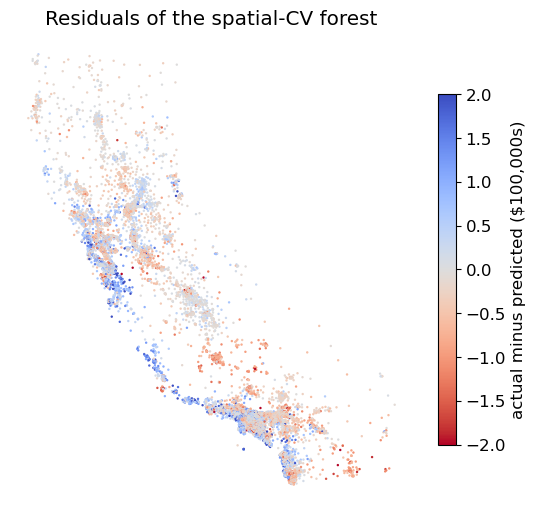

Moran's I of the residuals: 0.491 (pseudo p 0.01)


In [16]:
resid = y.values - pred_spatial
fig, ax = plt.subplots(figsize=(6.5, 6.5))
lim = 2.0
point_map(ax, df.x, df.y, resid, "coolwarm_r", -lim, lim, "Residuals of the spatial-CV forest", "actual minus predicted ($100,000s)")
plt.show()
w8 = weights.KNN.from_array(df[["x", "y"]].values, k=8)
w8.transform = "R"
np.random.seed(0)
mi = Moran(resid, w8, permutations=99)
print(f"Moran's I of the residuals: {mi.I:.3f} (pseudo p {mi.p_sim:.2f})")

Positive Moran's I means errors come in clumps: a region where the model predicts too low has neighbors where it also predicts too low. The model is missing something that varies in space, and the map shows where.

### 🔎 Try it yourself
Plot only the block groups where the absolute residual is above 1.5. Which part of the state do they come from?

## Part 9: What the forest uses

A forest has about two million nodes, so reading it is not an option. **Permutation importance** shuffles one feature in the *test* rows and measures how much the test $R^2$ falls: a large fall means the model leans on that feature. We hold out one spatial fold, fit on the rest, and shuffle there. A **partial dependence** curve shows the average prediction as one feature is moved across its range.

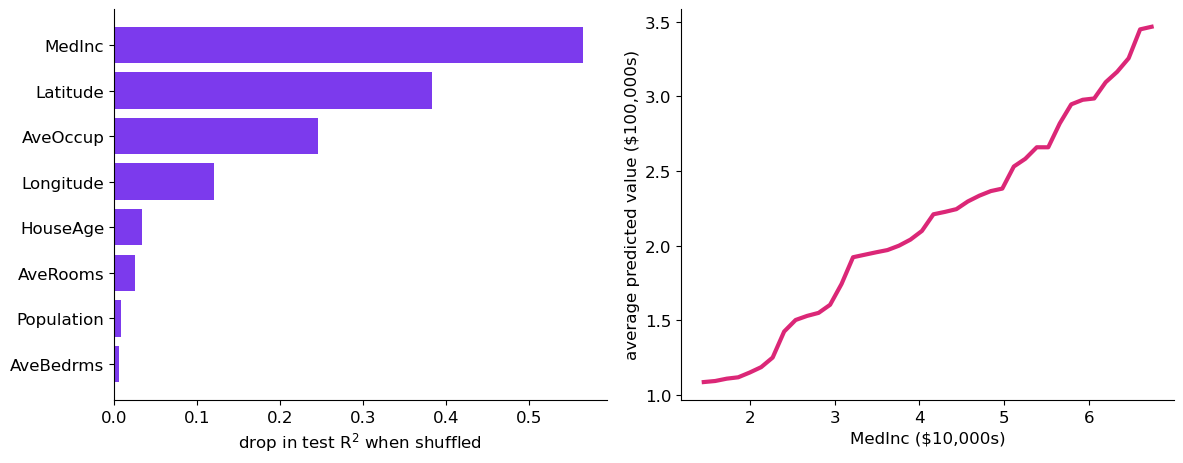

test R2 of this fold: 0.714


In [17]:
train, test = next(model_selection.GroupKFold(5).split(df[F8], y, groups=block))
rf_f = ensemble.RandomForestRegressor(n_jobs=-1, random_state=0).fit(df[F8].iloc[train], y.iloc[train])
imp = inspection.permutation_importance(rf_f, df[F8].iloc[test], y.iloc[test], n_repeats=5, random_state=0, n_jobs=-1)
order = np.argsort(imp.importances_mean)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.8))
a1.barh([F8[i] for i in order], imp.importances_mean[order], color=PURPLE)
a1.set_xlabel("drop in test R$^2$ when shuffled")
pdp = inspection.partial_dependence(rf_f, df[F8].iloc[test], ["MedInc"], grid_resolution=40)
a2.plot(pdp["values"][0], pdp["average"][0], color=MAGENTA, lw=3)
a2.set_xlabel("MedInc ($10,000s)"); a2.set_ylabel("average predicted value ($100,000s)")
plt.tight_layout(); plt.show()
print("test R2 of this fold:", round(rf_f.score(df[F8].iloc[test], y.iloc[test]), 3))

Income matters most, then latitude and people per household. The income curve is close to a rising line, which is why a line did reasonably well at the start. **Importance says what the model uses, not why house values depend on it**: latitude may stand in for climate, coastline, or the cost of land near big cities.

A caution: a partial dependence curve averages over every other feature, so it can hide a pattern that depends on them. Try the curve for `Latitude` in the box below and compare it with its importance bar.

### 🔎 Try it yourself
Call `inspection.partial_dependence(rf_f, df[F8].iloc[test], ["Latitude"])` and plot `pdp["values"][0]` against `pdp["average"][0]`. Does the curve look as important as the bar says?

## Learn More / Going Further

- **Other models.** Try `HistGradientBoostingRegressor`, `ExtraTreesRegressor`, or `sklearn.neural_network.MLPRegressor` on the same split and compare the spatial-fold $R^2$.
- **Other blocks.** Replace the KMeans blocks by a grid of 50 km squares (`(x // 50000, y // 50000)` as a group label) and see whether the gap changes.
- **Other metrics.** Compute the MAE and RMSE per spatial fold and map where each fold is hardest.
- **Capped values.** Drop the 992 capped block groups and refit. Does the line or the forest change more?
- **Local Moran.** Use `esda.Moran_Local` on the residuals to find clusters of large positive and negative errors.
- **Reading.** Fleischmann, *Spatial Data Science*, "Non-linear regression: spatial evaluation and model architecture": https://martinfleischmann.net/sds/tree_regression/hands_on.html. Roberts et al. (2017), Cross-validation strategies for data with temporal, spatial, hierarchical, or phylogenetic structure, *Ecography* 40(8), 913-929.
- **Stretch.** Tune the forest (`max_features`, `min_samples_leaf`) with `GridSearchCV(cv=GroupKFold(5))` and `groups=block`, so that tuning also respects space.